**← Previous:** [Calibration](04_calibration.ipynb)  
**→ Next:** [LGD Pipeline](06_LGD_pipeline.ipynb)

```text
LGD model development
├── Import & Setup
├── Limitation
├── Explore
├── Pre-processing
└── LGD estimators   
    ├── Empirical
    ├── Model
    └── Stochastic
```

#### Import & Setup 

In [1]:
# Init work dir

from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Standard modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Framework

from credit_risk_framework.feature_engineering import create_target_def12, SpecialMappings
from credit_risk_framework.metrics import calculate_regression_metrics
from credit_risk_framework.modelling import fit_lgd, transform_lgd
from credit_risk_framework.plots import plot_lgd_distribution_comparison, plot_variable_explore, plot_pred_vs_obs_lgd, plot_var_vs_lgd  
from credit_risk_framework.preprocessing import input_load, time_split, ReplaceMinusOne
from credit_risk_framework.validation import model_selector, missing_summary

# Dataset specific settings

from credit_risk_framework import settings_dataset_unsecured as settings

# ML modules

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Configuration

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
from sklearn import set_config; set_config(transform_output="pandas") # set sklearn output: pandas

In [3]:
# load input file

full_dataset = input_load(2019, 2020, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)

# create def12

full_dataset, dr_summary = create_target_def12(full_dataset, 
                                               settings.COLUMN_DATE,
                                               settings.COLUMN_YEAR, 
                                               settings.COLUMN_TARGET_DATE,
                                               settings.COLUMN_TARGET, 
                                               verbose=False,
                                            )

# split train/test

windows = {"train": (2019, 2019), "test":  (2020, 2020)}

splits = time_split(full_dataset, settings.COLUMN_YEAR, windows, target="LossGivenDefault")

ds_trai = splits["train"]["df"]
ds_test = splits["test"]["df"]
X_trai  = splits["train"]["X"]
X_test  = splits["test"]["X"]
y_trai  = splits["train"]["y"]
y_test  = splits["test"]["y"]


SPLIT SUMMARY

TRAIN
Years        : 2019 - 2019
Shape (X, y) : (28487, 112), (28487,)

Year distribution
Year
2019    28487
Name: count, dtype: int64

Target mean : 0.1633
------------------------------------------------------------

TEST
Years        : 2020 - 2020
Shape (X, y) : (19959, 112), (19959,)

Year distribution
Year
2020    19959
Name: count, dtype: int64

Target mean : 0.1365
------------------------------------------------------------


#### Limitation


Analysis reveals a structural change in the LossGivenDefault variable across loan origination years. While the period **2019–2020** contains zero-loss observations (full-recoveries), earlier and later years show higher and constrained LGD values, suggesting differences in the underlying target definition or calculation methodology. Since the objective of this project is to demonstrate a modular LGD estimation rather than validate the dataset itself, **LossGivenDefault is treated as the observed target variable**, and the LGD models are developed on the 2019–2020 period, where the target behaves consistently.

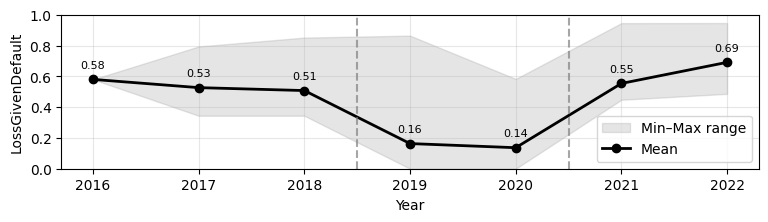

In [4]:
# explore "LossGivenDefault" across years

ds_all_years = input_load(2016, 2022, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)
plot_variable_explore(ds_all_years, variable="LossGivenDefault", column_year=settings.COLUMN_YEAR, breaks=[2018.5, 2020.5])

#### Explore

In [5]:
# explore lgd & recovery

lgd_cols = [
    feature
    for feature, metadata in settings.FEATURES.items()
    if  metadata["lgd_eligible"] is True
    #and metadata["type"] == "categorical" 
]

for variable in lgd_cols:
    if splits["train"]["df"][variable].nunique() <= 20:
        print(variable)
        plot_var_vs_lgd(splits["train"]["df"], variable)

CreditScoreEeMini


,CreditScoreEeMini,count,LGD(mean),LGD=0,LGD>0,Recovery(%)
0,500.000000,21,0.118,16,5,76.190
1,600.000000,244,0.138,173,71,70.902
2,700.000000,258,0.172,176,82,68.217
3,800.000000,601,0.164,419,182,69.717
4,900.000000,393,0.187,257,136,65.394
5,1000.000000,3362,0.185,2143,1219,63.742


DebtToIncome


,DebtToIncome,count,LGD(mean),LGD=0,LGD>0,Recovery(%)
0,0.000000,4879,0.179,3184,1695,65.259


Education


,Education,count,LGD(mean),LGD=0,LGD>0,Recovery(%)
0,1.000000,954,0.140,735,219,77.044
1,2.000000,83,0.299,36,47,43.373
2,3.000000,1031,0.164,709,322,68.768
3,4.000000,2195,0.188,1387,808,63.189
4,5.000000,616,0.219,317,299,51.461


... (4 outputs left out)

HomeOwnershipType


,HomeOwnershipType,count,LGD(mean),LGD=0,LGD>0,Recovery(%)
0,1.000000,1774,0.191,1120,654,63.134
1,2.000000,1108,0.176,737,371,66.516
2,3.000000,1149,0.158,802,347,69.800
3,4.000000,24,0.271,11,13,45.833
4,5.000000,58,0.228,33,25,56.897
5,6.000000,14,0.338,5,9,35.714
6,7.000000,28,0.338,9,19,32.143
7,8.000000,212,0.193,118,94,55.660
8,9.000000,5,0.323,1,4,20.000
9,10.000000,507,0.165,348,159,68.639


LoanDuration


,LoanDuration,count,LGD(mean),LGD=0,LGD>0,Recovery(%)
0,6,7,0.059,6,1,85.714
1,9,12,0.000,12,0,100.000
2,12,20,0.158,13,7,65.000
3,18,29,0.033,27,2,93.103
4,24,45,0.150,31,14,68.889
5,30,41,0.127,31,10,75.610
6,36,2007,0.183,1261,746,62.830
7,48,197,0.197,119,78,60.406
8,60,2521,0.179,1684,837,66.799


#### Pre-processing

In [6]:
# DEFINE NUMERICAL(+ORDINAL)/CATEGORICAL FEATURES

num_cols = [
    feature
    for feature, metadata in settings.FEATURES.items()
    if metadata["type"] in ["numeric", "ordinal"]
    and metadata["lgd_eligible"] is True
]

cat_cols = [
    feature
    for feature, metadata in settings.FEATURES.items()
    if metadata["type"] == "categorical"
    and metadata["lgd_eligible"] is True
]

# keep the LGD eligible features

lgd_eligible_features = num_cols + cat_cols
X_trai = X_trai[lgd_eligible_features]
X_test = X_test[lgd_eligible_features]

In [7]:
# -------------------------------------------------
# PREPROCESSOR FOR EMPIRICAL ESTIMATORS
# -------------------------------------------------

# numerical branch
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# categorical branch
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# empirical preprocessor
preprocessor_empirical = Pipeline([
    ("replace_minus_one", ReplaceMinusOne(verbose=False)),
    ("special_mappings", SpecialMappings(verbose=False)),
    ("features", ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]))
])

# fit transform
X_trai_emp = preprocessor_empirical.fit_transform(X_trai)
X_test_emp = preprocessor_empirical.transform(X_test)

# merge with target
ds_trai_emp = pd.concat([X_trai_emp, y_trai], axis=1)
ds_test_emp = pd.concat([X_test_emp, y_test], axis=1)

In [8]:
# -------------------------------------------------
# PREPROCESSOR FOR MODEL ESTIMATORS
# -------------------------------------------------

# numerical branch
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# categorical branch
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse_output=False
    ))
])

# ML preprocessor
preprocessor_model = Pipeline([
    ("replace_minus_one", ReplaceMinusOne(verbose=True)),
    ("special_mappings", SpecialMappings()),
    ("features", ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]))
])

# fit transform
X_trai_mod = preprocessor_model.fit_transform(X_trai) 
X_test_mod = preprocessor_model.transform(X_test)

# merge with target
ds_trai_mod = pd.concat([X_trai_mod, y_trai], axis=1)
ds_test_mod = pd.concat([X_test_mod, y_test], axis=1)

## LGD estimation

#### Fit & Evaluate [empirical estimators]

In [9]:
# initialise experiments

experiments = [
    ("experiment A", "historical_avg", None),
    ("experiment B", "univariate", "num__Age"),
    ("experiment C", "univariate", "cat__Gender"),
    ("experiment D", "univariate", "num__Amount"),
    ("experiment E", "univariate", "num__Interest"),
    ("experiment F", "univariate", "num__LoanDuration"),
    ("experiment G", "univariate", "cat__Education"),
    ("experiment H", "univariate", "num__EmploymentDurationCurrentEmployer"),
    ("experiment I", "univariate", "cat__HomeOwnershipType"),
    ("experiment J", "univariate", "num__IncomeTotal"),
    ("experiment K", "univariate", "num__ExistingLiabilities"),
    ("experiment L", "univariate", "num__LiabilitiesTotal"),
    ("experiment M", "univariate", "num__CreditScoreEeMini"),
    ("experiment N", "univariate", "num__NoOfPreviousLoansBeforeLoan"),
    ("experiment O", "univariate", "num__AmountOfPreviousLoansBeforeLoan"),
]

experiment_metrics = []

In [10]:
# loop on experiments

for experiment, method, variable in experiments:

    # fit lgds on training dataset
    
    lgd_model = fit_lgd(ds_trai_emp, method=method, one_variable=variable)

    # transform lgds on training dataset 

    pred_trai   = transform_lgd(ds_trai_emp, lgd_model)

    # transform lgds on testing dataset

    pred_test   = transform_lgd(ds_test_emp, lgd_model)

    # evaluate: calculate metrics

    metrics_trai = calculate_regression_metrics(pred_trai["LossGivenDefault"], pred_trai["LGD"], dataset_name="TRAIN", verbose=False)   
    metrics_test = calculate_regression_metrics(pred_test["LossGivenDefault"], pred_test["LGD"], dataset_name="TEST" , verbose=False)   

    # append

    metrics_trai["Experiment"] = experiment
    metrics_trai["Dataset"]    = "TRAIN"
    metrics_trai["Method"]     = method
    metrics_trai["Variable"]   = variable
    experiment_metrics.append(metrics_trai)

    metrics_test["Experiment"] = experiment
    metrics_test["Dataset"]    = "TEST"
    metrics_test["Method"]     = method
    metrics_test["Variable"]   = variable
    experiment_metrics.append(metrics_test)

    # evaluate: visually
    
    #plot_pred_vs_obs_lgd(pred_trai, pred_test)
    #plot_lgd_distribution_comparison(pred_trai)

# put together

experiment_metrics_EMPIRICAL = pd.DataFrame(experiment_metrics)
#display(experiment_metrics_EMPIRICAL.sort_values(by=["Experiment", "Dataset"], ascending=[False, False]))


LGD estimation method: historical_avg
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate
LGD estimation method: univariate


#### Fit & Evaluate [model estimators]

In [11]:
# initialise experiments

experiments = [
    ("experiment P", "linear_regression", None),
    ("experiment Q", "gradient_boosting_regression", None),
]

experiment_metrics = []

In [12]:
# loop on experiments

for experiment, method, variable in experiments:

    # fit lgds on training dataset
    
    lgd_model = fit_lgd(ds_trai_mod, method=method, one_variable=variable)

    # transform lgds on training dataset 

    pred_trai   = transform_lgd(ds_trai_mod, lgd_model)

    # transform lgds on testing dataset

    pred_test   = transform_lgd(ds_test_mod, lgd_model)

    # evaluate: calculate metrics

    metrics_trai = calculate_regression_metrics(pred_trai["LossGivenDefault"], pred_trai["LGD"], dataset_name="TRAIN", verbose=False)   
    metrics_test = calculate_regression_metrics(pred_test["LossGivenDefault"], pred_test["LGD"], dataset_name="TEST" , verbose=False)   

    # append

    metrics_trai["Experiment"] = experiment
    metrics_trai["Dataset"]    = "TRAIN"
    metrics_trai["Method"]     = method
    metrics_trai["Variable"]   = variable
    experiment_metrics.append(metrics_trai)

    metrics_test["Experiment"] = experiment
    metrics_test["Dataset"]    = "TEST"
    metrics_test["Method"]     = method
    metrics_test["Variable"]   = variable
    experiment_metrics.append(metrics_test)

    # evaluate: visually
    
    #plot_pred_vs_obs_lgd(pred_trai, pred_test)
    #plot_lgd_distribution_comparison(pred_trai)

# put together

experiment_metrics_MODEL = pd.DataFrame(experiment_metrics)
#display(experiment_metrics_MODEL.sort_values(by=["Experiment", "Dataset"], ascending=[False, False]))


LGD estimation method: linear_regression
LGD estimation method: gradient_boosting_regression


#### Fit & Evaluate [stochastic estimator]

In [13]:
# initialise experiments

experiments = [
    ("experiment S", "stochastic", None),
]

experiment_metrics = []

LGD estimation method: stochastic
Zero LGD probability:     0.6711
Positive LGD probability: 0.3289

Positive LGD distribution:
  Empirical mean:     0.4967
  Beta mean:          0.4972
  Empirical variance: 0.006996
  Beta variance:      0.007007

Quantile | Empirical | Beta
0.10 | 0.3902 | 0.3889
0.25 | 0.4291 | 0.4397
0.50 | 0.4941 | 0.4971
0.75 | 0.5582 | 0.5547
0.90 | 0.6040 | 0.6055


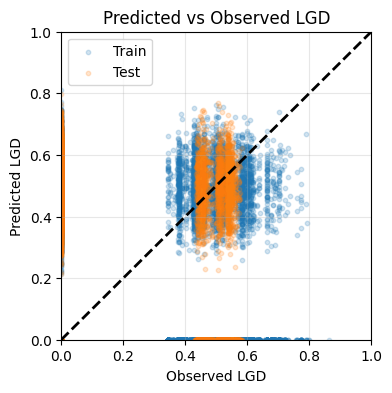

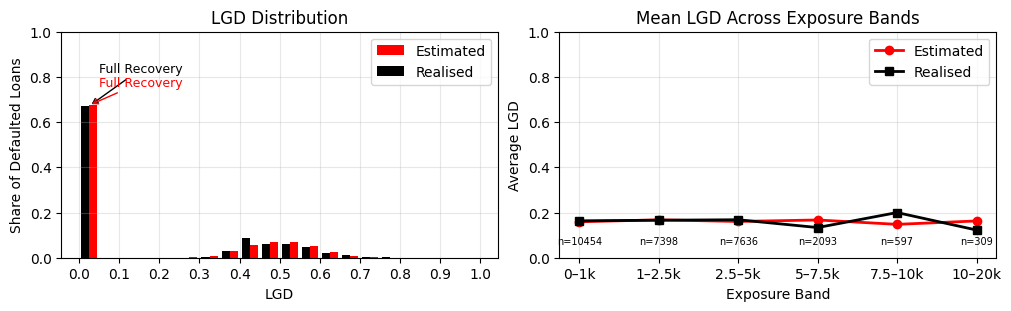

In [14]:
# loop on experiments

for experiment, method, variable in experiments:

    # fit lgds on training dataset
    
    lgd_model = fit_lgd(ds_trai_emp, method=method, one_variable=variable, verbose=True)
    
    # transform lgds on training dataset 

    pred_trai   = transform_lgd(ds_trai_emp, lgd_model)

    # transform lgds on testing dataset

    pred_test   = transform_lgd(ds_test_emp, lgd_model)

    # evaluate: calculate metrics

    metrics_trai = calculate_regression_metrics(pred_trai["LossGivenDefault"], pred_trai["LGD"], dataset_name="TRAIN", verbose=False)   
    metrics_test = calculate_regression_metrics(pred_test["LossGivenDefault"], pred_test["LGD"], dataset_name="TEST" , verbose=False)   

    # append

    metrics_trai["Experiment"] = experiment
    metrics_trai["Dataset"]    = "TRAIN"
    metrics_trai["Method"]     = method
    metrics_trai["Variable"]   = variable
    experiment_metrics.append(metrics_trai)

    metrics_test["Experiment"] = experiment
    metrics_test["Dataset"]    = "TEST"
    metrics_test["Method"]     = method
    metrics_test["Variable"]   = variable
    experiment_metrics.append(metrics_test)

    # evaluate: visually
    
    plot_pred_vs_obs_lgd(pred_trai, pred_test)
    plot_lgd_distribution_comparison(pred_trai)

# put together

experiment_metrics_STOCH = pd.DataFrame(experiment_metrics)
#display(experiment_metrics_STOCH.sort_values(by=["Experiment", "Dataset"], ascending=[False, False]))

#### Select 

In [15]:
# put metrics together: EMPIRICAL, MODEL, STOCHASTIC estimators

experiment_metrics_ALL = pd.concat([experiment_metrics_EMPIRICAL, experiment_metrics_MODEL, experiment_metrics_STOCH], axis=0)

# model selector: better correlation

selection_table, best_model = model_selector(experiment_metrics_ALL, metric="CORR", higher_is_better=True)
display(best_model)

# model selector: better distributional fit

selection_table, best_model = model_selector(experiment_metrics_ALL, metric="KS", higher_is_better=False)
display(best_model)

Dataset,Experiment,Method,Variable,Test CORR,Train CORR,Generalization Gap
4,experiment E,univariate,Interest,0.101673,0.157271,0.055599


Dataset,Experiment,Method,Variable,Test KS,Train KS,Generalization Gap
17,experiment S,stochastic,NaN,0.071246,0.03219,0.039056
